# UTCI Heatwave Jawa 1996–2025 — Combined Journal-Style Notebook

Notebook gabungan ini merangkum workflow UTCI yang sebelumnya tercecer di beberapa notebook menjadi **satu alur plot utama** bergaya jurnal internasional.

## Output utama
1. **Peta klimatologi mean daily UTCImax** 1996–2025.
2. **Perbandingan threshold kalender-harian P90 dan P95** + selisih P95−P90.
3. **Sensitivitas spasial** P90/P95 × minimum 3/4/5 hari (ditampilkan untuk HWF).
4. **Sensitivitas time series** untuk HWN, HWF, HWD, HWA, HWM.
5. **Peta karakteristik heatwave UTCI**: HWN, HWF, HWD, HWA, HWM.
6. **Time series karakteristik heatwave UTCI** dengan annual series, running mean 5 tahun, tren Theil–Sen, dan p-value Kendall.

## Definisi metodologis
- Definisi utama default: **P90-D3** (`MAIN_SCENARIO = "P90_D3"`).
- Sensitivitas: **P90/P95 × D3/D4/D5**.
- Threshold dihitung dengan **calendar-day percentile** memakai **15-day centered window**.
- Heatwave event: `UTCImax > threshold` selama sedikitnya `D` hari berturut-turut.
- **HWN** = jumlah event per tahun.
- **HWF** = total hari heatwave per tahun.
- **HWD** = durasi maksimum heatwave per tahun.
- **HWA** = nilai maksimum UTCImax pada hari heatwave (mode absolut) atau exceedance maksimum di atas threshold (mode excess).
- **HWM** = nilai rata-rata UTCImax pada hari heatwave (mode absolut) atau exceedance rata-rata di atas threshold (mode excess).

## Catatan input
Notebook ini **langsung memakai file daily maximum UTCI** hasil STEP 2 (`03_utci_dailymax_1996_2025_C_jawa.nc`). Jadi lebih ringan daripada mengulang QC file jam-jaman dari nol. Kalau file itu belum ada, jalankan dulu notebook STEP 1–2 milikmu.


> **Visualisasi SMOOTH:** Figure 1, 2, 3, dan 5 memakai interpolasi linear khusus tampilan, clipping poligon Jawa, dan dukungan grid native. Angka pada grid, threshold, deteksi kejadian, indeks, dan tren tidak diubah. Set `DISPLAY_RENDER = "native"` untuk pemeriksaan resolusi asli.


## 0. Instalasi paket (jalankan hanya jika perlu)

```bash
pip install numpy pandas xarray netCDF4 matplotlib cartopy shapely scipy openpyxl
```


In [1]:

from pathlib import Path

# Folder hasil UTCI
RESULT_DIR = Path(r"D:\Daps\Data\Hasil_UTCI")

print("Folder ditemukan:", RESULT_DIR.exists())

# Cari semua file NetCDF UTCI daily maximum
files = sorted(RESULT_DIR.rglob("*dailymax*.nc"))

print("\nJumlah file ditemukan:", len(files))

for i, file in enumerate(files, start=1):
    print(f"{i}. {file}")


Folder ditemukan: True

Jumlah file ditemukan: 0


In [2]:
# ============================================================
# 1. IMPORT + KONFIGURASI UTAMA
# ============================================================

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import theilslopes, kendalltau

import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader

warnings.filterwarnings("ignore", category=RuntimeWarning)

# ------------------------------------------------------------
# PATH — UBAH JIKA FOLDERMU BERBEDA
# ------------------------------------------------------------
RESULT_DIR = Path(r"D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025")
INPUT_FILE = RESULT_DIR / "03_utci_dailymax_1996_2025_C_jawa.nc"
OUTPUT_DIR = RESULT_DIR / "UTCI_Heatwave_Jawa_Journal_Combined_Output"
PLOT_DIR = OUTPUT_DIR / "plots"
DATA_DIR = OUTPUT_DIR / "data"

for folder in [OUTPUT_DIR, PLOT_DIR, DATA_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# PERIODE DAN DEFINISI HEATWAVE
# ------------------------------------------------------------
START_YEAR = 1996
END_YEAR = 2025
YEARS = np.arange(START_YEAR, END_YEAR + 1, dtype=int)

WINDOW_DAYS = 15
WINDOW_HALF = WINDOW_DAYS // 2
PERCENTILES = [90, 95]
MIN_DURATIONS = [3, 4, 5]
SCENARIOS = [f"P{p}_D{d}" for p in PERCENTILES for d in MIN_DURATIONS]
MAIN_SCENARIO = "P90_D3"

# HWA/HWM untuk figure utama
INTENSITY_MODE = "absolute"   # pilih: "absolute" atau "excess"

# PETA + OUTPUT
MAP_EXTENT = [105.0, 115.0, -9.2, -5.5]
FIG_DPI = 800
# Tampilan halus mengikuti referensi UTCI Jawa: interpolasi visual saja.
DISPLAY_RENDER = "smooth"  # ubah ke "native" untuk melihat piksel grid 0.25°
DISPLAY_NX = 900
DISPLAY_NY = 340

SAVE_PDF = True
ROBUST_COLOR_LIMITS = True

# STYLE JURNAL
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.titlesize": 14,
    "axes.linewidth": 0.8,
    "savefig.facecolor": "white",
    "figure.facecolor": "white",
})

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"File daily maximum UTCI tidak ditemukan:\n{INPUT_FILE}\n"
        "Jalankan dulu UTCI STEP 2 atau ubah path INPUT_FILE."
    )

if WINDOW_DAYS % 2 == 0:
    raise ValueError("WINDOW_DAYS harus ganjil.")

if MAIN_SCENARIO not in SCENARIOS:
    raise ValueError(f"MAIN_SCENARIO harus salah satu dari {SCENARIOS}")

if INTENSITY_MODE not in {"absolute", "excess"}:
    raise ValueError("INTENSITY_MODE harus 'absolute' atau 'excess'.")

print("INPUT FILE     :", INPUT_FILE)
print("OUTPUT DIR     :", OUTPUT_DIR)
print("Periode        :", START_YEAR, "–", END_YEAR)
print("Main scenario  :", MAIN_SCENARIO)
print("All scenarios  :", SCENARIOS)
print("Intensity mode :", INTENSITY_MODE)


INPUT FILE     : D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\03_utci_dailymax_1996_2025_C_jawa.nc
OUTPUT DIR     : D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output
Periode        : 1996 – 2025
Main scenario  : P90_D3
All scenarios  : ['P90_D3', 'P90_D4', 'P90_D5', 'P95_D3', 'P95_D4', 'P95_D5']
Intensity mode : absolute


## 2. Buka daily maximum UTCI dan QC cepat

Cell ini membaca hasil STEP 2 dan memeriksa:
- nama variabel `utci_max`;
- kontinuitas tanggal 1996–2025;
- grid valid Jawa;
- rentang nilai UTCI.


In [3]:
# ============================================================
# 2. LOAD INPUT DAILY MAX UTCI
# ============================================================

ds = xr.open_dataset(
    INPUT_FILE,
    engine="netcdf4",
    decode_times=True,
    decode_timedelta=False,
)

if "utci_max" not in ds.data_vars:
    raise ValueError("Variabel 'utci_max' tidak ditemukan di INPUT_FILE.")

utci = ds["utci_max"].transpose("time", "latitude", "longitude")
values = np.asarray(utci.values, dtype=np.float32)
lat = np.asarray(ds["latitude"].values, dtype=float)
lon = np.asarray(ds["longitude"].values, dtype=float)
dates = pd.DatetimeIndex(utci["time"].values)

expected_dates = pd.date_range(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31", freq="D")
if len(dates) != len(expected_dates):
    raise ValueError("Jumlah hari input tidak sesuai 1996–2025.")
if len(dates[dates.duplicated()]) != 0:
    raise ValueError("Ada tanggal duplikat dalam data UTCI harian.")
if len(expected_dates.difference(dates)) != 0:
    raise ValueError("Ada tanggal yang hilang dalam data UTCI harian.")

valid = np.isfinite(values)
valid_grid = np.any(valid, axis=0)
if lon.max() < 105 or lon.min() > 115 or lat.max() < -9.2 or lat.min() > -5.5:
    raise ValueError("INPUT_FILE UTCI tidak mencakup Jawa; periksa path dan file NetCDF.")

print("Shape values :", values.shape)
print("Latitude     :", lat.min(), "s.d.", lat.max(), "| n =", len(lat))
print("Longitude    :", lon.min(), "s.d.", lon.max(), "| n =", len(lon))
print("Periode      :", dates.min(), "s.d.", dates.max())
print("Grid valid   :", int(valid_grid.sum()))
print("UTCI min     :", float(np.nanmin(values)), "°C")
print("UTCI max     :", float(np.nanmax(values)), "°C")


Shape values : (10958, 12, 36)
Latitude     : -8.75 s.d. -6.0 | n = 12
Longitude    : 105.75 s.d. 114.5 | n = 36
Periode      : 1996-01-01 00:00:00 s.d. 2025-12-31 00:00:00
Grid valid   : 176
UTCI min     : 19.581024169921875 °C
UTCI max     : 45.90130615234375 °C


In [4]:
from shapely.ops import unary_union

## 3. Helper plotting jurnal

Semua peta memakai:
- extent yang sama;
- coastline;
- batas provinsi Jawa/DI Yogyakarta;
- gridline label minimal;
- shared helper untuk robust color limits.


In [5]:
# ============================================================
# 3. HELPER PLOTTING
# ============================================================

# Batas administratif enam provinsi Jawa dari Natural Earth 10m.
# Cocokkan hanya atribut NAMA provinsi agar tidak salah akibat teks atribut lain.
JAVA_PROVINCE_ALIASES = {'Banten': ['banten'], 'DKI Jakarta': ['jakarta raya', 'jakarta', 'dki jakarta', 'daerah khusus ibukota jakarta'], 'Jawa Barat': ['west java', 'jawa barat'], 'Jawa Tengah': ['central java', 'jawa tengah'], 'DI Yogyakarta': ['yogyakarta', 'di yogyakarta', 'daerah istimewa yogyakarta', 'special region of yogyakarta'], 'Jawa Timur': ['east java', 'jawa timur']}
JAVA_PROVINCE_ORDER = ['Banten', 'DKI Jakarta', 'Jawa Barat', 'Jawa Tengah', 'DI Yogyakarta', 'Jawa Timur']
JAVA_PROVINCE_SHORT = {'Banten': 'Banten', 'DKI Jakarta': 'DKI', 'Jawa Barat': 'Jabar', 'Jawa Tengah': 'Jateng', 'DI Yogyakarta': 'DIY', 'Jawa Timur': 'Jatim'}

def load_java_province_geometries():
    admin1_file = shpreader.natural_earth(
        resolution="10m", category="cultural", name="admin_1_states_provinces"
    )
    found = {p: [] for p in JAVA_PROVINCE_ORDER}
    for rec in shpreader.Reader(admin1_file).records():
        attrs = rec.attributes
        country = " ".join(str(attrs.get(k, "")).lower()
            for k in ("admin", "geonunit", "iso_a3", "adm0_a3", "iso_a2"))
        if not any(key in country for key in ("indonesia", "idn")):
            continue
        values = [str(attrs.get(k, "")).strip().lower()
                  for k in ("name", "name_en", "name_local", "name_alt", "woe_name", "gn_name")]
        for province, aliases in JAVA_PROVINCE_ALIASES.items():
            if any(value == alias for value in values for alias in aliases):
                found[province].append(rec.geometry)
    missing = [p for p, geometries in found.items() if not geometries]
    if missing:
        raise RuntimeError(
            "Batas provinsi Jawa tidak ditemukan di Natural Earth: " + ", ".join(missing)
            + ". Periksa versi data Natural Earth admin_1_states_provinces."
        )
    return {p: unary_union(geometries) for p, geometries in found.items()}
province_geometries = load_java_province_geometries()
java_geometry = unary_union(list(province_geometries.values()))
lon2d, lat2d = np.meshgrid(lon, lat)
try:
    from shapely import contains_xy as _java_contains_xy
except ImportError:
    from shapely.vectorized import contains as _java_contains_xy
java_mask = np.asarray(_java_contains_xy(java_geometry, lon2d, lat2d), dtype=bool)
valid_grid &= java_mask
# Mask semua tanggal di luar Jawa agar threshold/metrics pun tidak mencakup wilayah lain.
values[:, ~java_mask] = np.nan
valid[:, ~java_mask] = False
if not np.any(valid_grid):
    raise ValueError("Tidak ada grid UTCI valid di Jawa; periksa INPUT_FILE dan resolusi spasial.")
province_masks = {
    p: np.asarray(_java_contains_xy(geom, lon2d, lat2d), dtype=bool) & valid_grid
    for p, geom in province_geometries.items()
}
print("Grid UTCI valid Jawa:", int(valid_grid.sum()))
for p in JAVA_PROVINCE_ORDER:
    print(f"  {p:20s}: {int(province_masks[p].sum())} grid")


def masked(field):
    arr = np.asarray(field, dtype=float).copy()
    arr[~valid_grid] = np.nan
    return arr


def robust_limits(arrays, low=2, high=98, symmetric=False):
    if not isinstance(arrays, (list, tuple)):
        arrays = [arrays]
    vals = []
    for a in arrays:
        a = np.asarray(a)
        f = a[np.isfinite(a)]
        if f.size:
            vals.append(f)
    if not vals:
        return (-1.0, 1.0) if symmetric else (0.0, 1.0)
    vals = np.concatenate(vals)
    if symmetric:
        vmax = float(np.nanpercentile(np.abs(vals), high))
        if (not np.isfinite(vmax)) or (vmax == 0):
            vmax = float(np.nanmax(np.abs(vals))) if vals.size else 1.0
        return -vmax, vmax
    if ROBUST_COLOR_LIMITS:
        vmin = float(np.nanpercentile(vals, low))
        vmax = float(np.nanpercentile(vals, high))
    else:
        vmin = float(np.nanmin(vals))
        vmax = float(np.nanmax(vals))
    if np.isclose(vmin, vmax):
        vmin = float(np.nanmin(vals))
        vmax = float(np.nanmax(vals))
        if np.isclose(vmin, vmax):
            vmax = vmin + 1e-6
    return vmin, vmax


def setup_map_ax(ax, left_labels=True, bottom_labels=True):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.coastlines(resolution="10m", linewidth=0.6)
    for geom in province_geometries.values():
        ax.add_geometries(
            [geom],
            crs=ccrs.PlateCarree(),
            facecolor="none",
            edgecolor="0.25",
            linewidth=0.45,
            zorder=5,
        )
    gl = ax.gridlines(
        draw_labels=True,
        linewidth=0.25,
        linestyle=":",
        alpha=0.45,
        x_inline=False,
        y_inline=False,
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = left_labels
    gl.bottom_labels = bottom_labels
    gl.xlabel_style = {"size": 7}
    gl.ylabel_style = {"size": 7}


def save_figure(fig, stem):
    png = PLOT_DIR / f"{stem}.png"
    fig.savefig(png, dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    if SAVE_PDF:
        pdf = PLOT_DIR / f"{stem}.pdf"
        fig.savefig(pdf, dpi=FIG_DPI, bbox_inches="tight", facecolor="white")
    print("Tersimpan:", png)
    return png


# ============================================================
# SMOOTH SPATIAL RENDERING — ADAPTED FROM THE JAVA NOTEBOOK
# ============================================================
# Interpolasi LINEAR hanya untuk gambar; tidak memodifikasi array
# Tmax/UTCI, threshold, event, annual metrics, ataupun statistik tren.
from scipy.interpolate import griddata, RegularGridInterpolator
from shapely.ops import unary_union
try:
    from shapely import contains_xy as _smooth_contains_xy
except ImportError:
    from shapely.vectorized import contains as _smooth_contains_xy

# Tepi laut/pulau mengikuti poligon Natural Earth 10m. Grid tanpa
# observasi native tetap kosong agar pulau kecil tidak direkayasa.
_SMOOTH_LAND_GEOMETRY = java_geometry
_FINE_GRID_CACHE = None


def _fine_grid():
    global _FINE_GRID_CACHE
    if _FINE_GRID_CACHE is None:
        fx = np.linspace(MAP_EXTENT[0], MAP_EXTENT[1], DISPLAY_NX)
        fy = np.linspace(MAP_EXTENT[2], MAP_EXTENT[3], DISPLAY_NY)
        fxx, fyy = np.meshgrid(fx, fy)
        land_inside = np.asarray(
            _smooth_contains_xy(_SMOOTH_LAND_GEOMETRY, fxx, fyy), dtype=bool
        )
        _FINE_GRID_CACHE = fx, fy, fxx, fyy, land_inside
    return _FINE_GRID_CACHE


def smooth_for_display(field):
    """Fine-grid peta saja; masked outside Jawa AND outside native support."""
    z = masked(field)       # tidak mengubah input
    good = np.isfinite(z)
    if good.sum() < 4:
        raise ValueError("Minimal empat grid darat valid dibutuhkan untuk display smooth.")

    fx, fy, fxx, fyy, land_inside = _fine_grid()
    gx, gy = np.meshgrid(lon, lat)
    samples = np.column_stack((gx[good], gy[good]))
    values_valid = z[good]

    # Sama dengan referensi Jawa: linear interpolation, lalu nearest
    # HANYA pada tepian domain yang tak dijangkau triangulasi.
    fine_values = griddata(samples, values_valid, (fxx, fyy), method="linear")
    missing_inside = land_inside & ~np.isfinite(fine_values)
    if np.any(missing_inside):
        nearest = griddata(samples, values_valid, (fxx, fyy), method="nearest")
        fine_values[missing_inside] = nearest[missing_inside]

    # Batasi ke footprint dari grid native yang memang memiliki data;
    # tidak menciptakan cakupan baru pada pulau terpencil/titik kosong.
    lat_sort = np.argsort(lat)
    lon_sort = np.argsort(lon)
    native_footprint = RegularGridInterpolator(
        (lat[lat_sort], lon[lon_sort]), good[np.ix_(lat_sort, lon_sort)].astype(np.uint8),
        method="nearest", bounds_error=False, fill_value=0,
    )
    query_points = np.column_stack((fyy.ravel(), fxx.ravel()))
    supported = native_footprint(query_points).reshape(fxx.shape).astype(bool)
    fine_values[~(land_inside & supported)] = np.nan
    return fx, fy, fine_values


def draw_spatial_field(ax, field, cmap="YlOrRd", vmin=None, vmax=None,
                       norm=None, render=None):
    """Matplotlib QuadMesh; switch DISPLAY_RENDER to 'native' for QC."""
    mode = DISPLAY_RENDER if render is None else render
    z = masked(field)
    cmap_obj = mpl.colormaps[cmap].copy()
    cmap_obj.set_bad("white", alpha=0.0)
    kw = dict(cmap=cmap_obj, norm=norm,
              transform=ccrs.PlateCarree(), rasterized=True, zorder=2)
    if norm is None:
        kw.update(vmin=vmin, vmax=vmax)
    if mode == "native":
        return ax.pcolormesh(lon, lat, np.ma.masked_invalid(z),
                             shading="nearest", **kw)
    if mode == "smooth":
        fx, fy, fine = smooth_for_display(z)
        return ax.pcolormesh(fx, fy, np.ma.masked_invalid(fine),
                             shading="auto", **kw)
    raise ValueError("DISPLAY_RENDER harus 'smooth' atau 'native'.")


Grid UTCI valid Jawa: 176
  Banten              : 10 grid
  DKI Jakarta         : 1 grid
  Jawa Barat          : 50 grid
  Jawa Tengah         : 47 grid
  DI Yogyakarta       : 3 grid
  Jawa Timur          : 65 grid


## 4. Figure 1 — Peta spatial mean daily UTCImax

Ini bukan HWA/HWM. Ini adalah **klimatologi rata-rata semua nilai daily maximum UTCI** periode 1996–2025.


Tersimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\plots\FIG01_Mean_Daily_UTCImax_Jawa_1996_2025.png


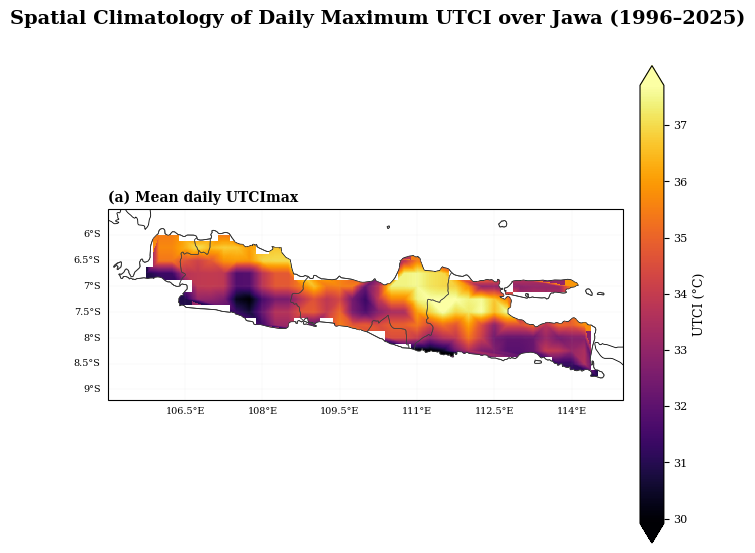

In [6]:
# ============================================================
# FIGURE 1 — MEAN DAILY UTCIMAX CLIMATOLOGY
# ============================================================

mean_daily_utci = masked(np.nanmean(values, axis=0))
if not np.isfinite(mean_daily_utci).any():
    raise ValueError("Peta UTCI Jawa kosong; periksa NetCDF dan mask.")
vmin, vmax = robust_limits(mean_daily_utci, low=1, high=99)

fig = plt.figure(figsize=(7.2, 6.2))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
mesh = draw_spatial_field(
        ax, mean_daily_utci, cmap="inferno", vmin=vmin, vmax=vmax,
    )
setup_map_ax(ax, left_labels=True, bottom_labels=True)
ax.set_title("(a) Mean daily UTCImax", fontweight="bold", loc="left", pad=5)
cb = fig.colorbar(mesh, ax=ax, orientation="vertical", fraction=0.046, pad=0.03, extend="both", extendfrac=0.045, extendrect=False)
cb.set_label("UTCI (°C)")

fig.suptitle(
    f"Spatial Climatology of Daily Maximum UTCI over Jawa ({START_YEAR}–{END_YEAR})",
    fontweight="bold",
    y=0.97,
)

save_figure(fig, "FIG01_Mean_Daily_UTCImax_Jawa_1996_2025")
plt.show()
plt.close(fig)


## 5. Threshold kalender-harian P90 dan P95

- Kalender referensi memakai **365 hari**.
- 29 Februari tidak dipakai saat membentuk klimatologi.
- Threshold 29 Februari saat diproyeksikan kembali ke deret waktu harian diambil dari rata-rata threshold 28 Februari dan 1 Maret.


In [7]:
# ============================================================
# 5. CALENDAR-DAY P90 / P95 THRESHOLD (15-DAY WINDOW)
# ============================================================

# Template non-leap year untuk indeks 0..364
cal_template = pd.date_range("2001-01-01", "2001-12-31", freq="D")
month_day_template = [(d.month, d.day) for d in cal_template]
month_day_to_index = {md: i for i, md in enumerate(month_day_template)}

clim_index = np.full(len(dates), -1, dtype=np.int16)
for t, date in enumerate(dates):
    md = (date.month, date.day)
    if md == (2, 29):
        clim_index[t] = -1
    else:
        clim_index[t] = month_day_to_index[md]

nlat, nlon = values.shape[1], values.shape[2]
threshold_calendar = np.full((len(PERCENTILES), 365, nlat, nlon), np.nan, dtype=np.float32)
sample_counts = []

valid_clim = clim_index >= 0

for d in range(365):
    window_days = [(d + off) % 365 for off in range(-WINDOW_HALF, WINDOW_HALF + 1)]
    time_mask = valid_clim & np.isin(clim_index, window_days)
    sample = values[time_mask, :, :]
    sample_counts.append(sample.shape[0])
    p_result = np.nanpercentile(sample, PERCENTILES, axis=0).astype(np.float32)
    threshold_calendar[:, d, :, :] = p_result

thresholds = {
    f"P{p}": threshold_calendar[i]
    for i, p in enumerate(PERCENTILES)
}

threshold_ds = xr.Dataset(
    {
        "P90": (("dayofyear", "latitude", "longitude"), threshold_calendar[0]),
        "P95": (("dayofyear", "latitude", "longitude"), threshold_calendar[1]),
    },
    coords={
        "dayofyear": np.arange(1, 366, dtype=np.int16),
        "latitude": lat,
        "longitude": lon,
    },
)

threshold_file = DATA_DIR / "UTCI_Thresholds_P90_P95_Calendar15day_1996_2025.nc"
threshold_ds.to_netcdf(threshold_file)
print("Threshold file:", threshold_file)
print("Sample count min/max:", min(sample_counts), "/", max(sample_counts))


Threshold file: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\data\UTCI_Thresholds_P90_P95_Calendar15day_1996_2025.nc
Sample count min/max: 450 / 450


## 6. Figure 2 — Perbandingan P90 dan P95

Panel (a) dan (b) memakai skala warna yang sama, sedangkan panel (c) menampilkan **P95 − P90**.


Tersimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\plots\FIG02_P90_P95_Threshold_Comparison_UTCI.png


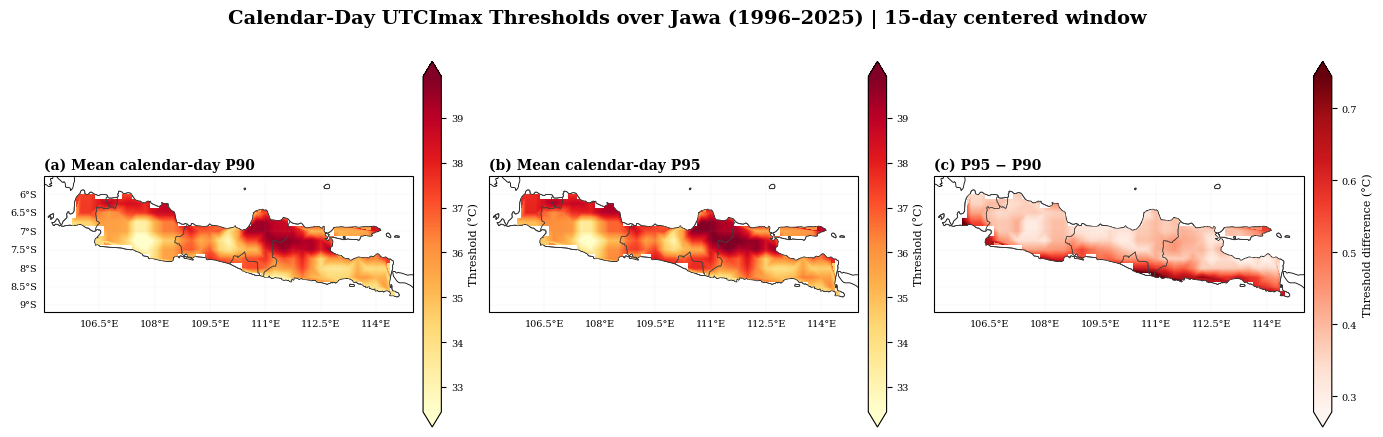

In [8]:
# ============================================================
# FIGURE 2 — P90 vs P95 THRESHOLD COMPARISON
# ============================================================

p90_mean = masked(np.nanmean(thresholds["P90"], axis=0))
p95_mean = masked(np.nanmean(thresholds["P95"], axis=0))
delta_95_90 = masked(p95_mean - p90_mean)

thr_vmin, thr_vmax = robust_limits([p90_mean, p95_mean], low=1, high=99)
d_vmin, d_vmax = robust_limits(delta_95_90, low=1, high=99)

fig = plt.figure(figsize=(14.0, 5.0))
gs = fig.add_gridspec(1, 3, wspace=0.12, left=0.04, right=0.96, bottom=0.12, top=0.86)

panels = [
    (p90_mean, "(a) Mean calendar-day P90", "YlOrRd", thr_vmin, thr_vmax, "Threshold (°C)"),
    (p95_mean, "(b) Mean calendar-day P95", "YlOrRd", thr_vmin, thr_vmax, "Threshold (°C)"),
    (delta_95_90, "(c) P95 − P90", "Reds", d_vmin, d_vmax, "Threshold difference (°C)"),
]

for i, (z, title, cmap, vmin, vmax, label) in enumerate(panels):
    ax = fig.add_subplot(gs[0, i], projection=ccrs.PlateCarree())
    mesh = draw_spatial_field(
        ax, z, cmap=cmap, vmin=vmin, vmax=vmax,
    )
    setup_map_ax(ax, left_labels=(i == 0), bottom_labels=True)
    ax.set_title(title, fontweight="bold", loc="left", pad=5)
    cb = fig.colorbar(mesh, ax=ax, orientation="vertical", fraction=0.046, pad=0.025, extend="both", extendfrac=0.045, extendrect=False)
    cb.set_label(label, fontsize=8)
    cb.ax.tick_params(labelsize=7)

fig.suptitle(
    f"Calendar-Day UTCImax Thresholds over Jawa ({START_YEAR}–{END_YEAR}) | {WINDOW_DAYS}-day centered window",
    fontweight="bold", y=0.96,
)

save_figure(fig, "FIG02_P90_P95_Threshold_Comparison_UTCI")
plt.show()
plt.close(fig)


## 7. Deteksi event heatwave dan lima karakteristik

Notebook menghitung semua enam skenario:
- `P90_D3`, `P90_D4`, `P90_D5`
- `P95_D3`, `P95_D4`, `P95_D5`

Semua hasil tahunan disimpan dalam dimensi:

`percentile × min_duration × year × latitude × longitude`


In [9]:
# ============================================================
# 7. EVENT DETECTION + ANNUAL METRICS
# ============================================================

idx_feb28 = month_day_to_index[(2, 28)]
idx_mar01 = month_day_to_index[(3, 1)]

def build_daily_threshold(calendar_threshold):
    """
    calendar_threshold: shape (365, lat, lon)
    return daily threshold over full 1996–2025 time axis
    """
    daily = np.full(values.shape, np.nan, dtype=np.float32)
    feb29_threshold = (calendar_threshold[idx_feb28] + calendar_threshold[idx_mar01]) / 2.0
    for t, date in enumerate(dates):
        if (date.month == 2) and (date.day == 29):
            daily[t] = feb29_threshold
        else:
            daily[t] = calendar_threshold[clim_index[t]]
    daily[~valid] = np.nan
    return daily


def heatwave_runs_1d(exceed_1d, min_duration):
    b = np.asarray(exceed_1d, dtype=bool)
    padded = np.concatenate(([False], b, [False]))
    changes = np.diff(padded.astype(np.int8))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]
    durations = ends - starts
    keep = durations >= min_duration
    valid_starts = starts[keep]
    valid_ends = ends[keep]
    valid_durations = durations[keep]
    event_mask = np.zeros(b.shape, dtype=bool)
    for start, end in zip(valid_starts, valid_ends):
        event_mask[start:end] = True
    return event_mask, valid_durations


years = np.arange(START_YEAR, END_YEAR + 1, dtype=np.int16)
date_years = dates.year.values
shape_out = (len(PERCENTILES), len(MIN_DURATIONS), len(years), nlat, nlon)

def new_metric_array():
    return np.full(shape_out, np.nan, dtype=np.float32)

HWN = new_metric_array()
HWF = new_metric_array()
HWD = new_metric_array()
HWA_excess = new_metric_array()
HWM_excess = new_metric_array()
HWA_abs = new_metric_array()
HWM_abs = new_metric_array()

grid_indices = np.argwhere(valid_grid)

for pi, percentile in enumerate(PERCENTILES):
    print("\n==============================")
    print(f"MEMPROSES P{percentile}")
    print("==============================")
    daily_threshold = build_daily_threshold(threshold_calendar[pi])
    exceed = valid & (values > daily_threshold)

    for di, min_duration in enumerate(MIN_DURATIONS):
        print(f"--- P{percentile} | ≥{min_duration} hari ---")
        for yi, year in enumerate(years):
            tidx = np.where(date_years == year)[0]
            ex_y = exceed[tidx]
            val_y = values[tidx]
            thr_y = daily_threshold[tidx]

            for ii, jj in grid_indices:
                event_mask, durations = heatwave_runs_1d(ex_y[:, ii, jj], min_duration)

                HWN[pi, di, yi, ii, jj] = float(len(durations))
                HWD[pi, di, yi, ii, jj] = float(durations.max()) if len(durations) > 0 else 0.0
                HWF[pi, di, yi, ii, jj] = float(event_mask.sum())

                if event_mask.any():
                    hw_abs = val_y[event_mask, ii, jj]
                    hw_excess = val_y[event_mask, ii, jj] - thr_y[event_mask, ii, jj]
                    HWA_abs[pi, di, yi, ii, jj] = float(np.nanmax(hw_abs))
                    HWM_abs[pi, di, yi, ii, jj] = float(np.nanmean(hw_abs))
                    HWA_excess[pi, di, yi, ii, jj] = float(np.nanmax(hw_excess))
                    HWM_excess[pi, di, yi, ii, jj] = float(np.nanmean(hw_excess))
                else:
                    HWA_abs[pi, di, yi, ii, jj] = np.nan
                    HWM_abs[pi, di, yi, ii, jj] = np.nan
                    HWA_excess[pi, di, yi, ii, jj] = np.nan
                    HWM_excess[pi, di, yi, ii, jj] = np.nan

# Simpan ke Dataset xarray
metrics_ds = xr.Dataset(
    {
        "HWN": (("percentile", "min_duration", "year", "latitude", "longitude"), HWN),
        "HWF": (("percentile", "min_duration", "year", "latitude", "longitude"), HWF),
        "HWD": (("percentile", "min_duration", "year", "latitude", "longitude"), HWD),
        "HWA_abs": (("percentile", "min_duration", "year", "latitude", "longitude"), HWA_abs),
        "HWM_abs": (("percentile", "min_duration", "year", "latitude", "longitude"), HWM_abs),
        "HWA_excess": (("percentile", "min_duration", "year", "latitude", "longitude"), HWA_excess),
        "HWM_excess": (("percentile", "min_duration", "year", "latitude", "longitude"), HWM_excess),
    },
    coords={
        "percentile": np.asarray(PERCENTILES, dtype=np.int16),
        "min_duration": np.asarray(MIN_DURATIONS, dtype=np.int8),
        "year": years,
        "latitude": lat,
        "longitude": lon,
    }
)

metrics_file = DATA_DIR / "UTCI_Heatwave_Metrics_AllScenarios_1996_2025.nc"
metrics_ds.to_netcdf(metrics_file)
print("Metrics file:", metrics_file)



MEMPROSES P90
--- P90 | ≥3 hari ---
--- P90 | ≥4 hari ---
--- P90 | ≥5 hari ---

MEMPROSES P95
--- P95 | ≥3 hari ---
--- P95 | ≥4 hari ---
--- P95 | ≥5 hari ---
Metrics file: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\data\UTCI_Heatwave_Metrics_AllScenarios_1996_2025.nc


## 8. Area-weighted annual mean untuk Jawa

Rata-rata regional dihitung memakai bobot `cos(latitude)` supaya sedikit lebih rapi dibanding mean grid mentah.


In [10]:
# ============================================================
# 8. AREA-WEIGHTED REGIONAL MEAN + TABEL ANNUAL
# ============================================================

lat_weights = np.cos(np.deg2rad(lat)).astype(float)
weights_2d = np.repeat(lat_weights[:, None], len(lon), axis=1)
weights_2d[~java_mask] = np.nan
weights_2d[~valid_grid] = np.nan


def area_weighted_mean(field2d):
    z = np.asarray(field2d, dtype=float)
    mask = np.isfinite(z) & np.isfinite(weights_2d)
    if not np.any(mask):
        return np.nan
    return float(np.nansum(z[mask] * weights_2d[mask]) / np.nansum(weights_2d[mask]))


scenario_results = {}
annual_rows = []

for pi, percentile in enumerate(PERCENTILES):
    for di, duration in enumerate(MIN_DURATIONS):
        scenario = f"P{percentile}_D{duration}"
        result = {
            "HWN": HWN[pi, di],
            "HWF": HWF[pi, di],
            "HWD": HWD[pi, di],
            "HWA_abs": HWA_abs[pi, di],
            "HWM_abs": HWM_abs[pi, di],
            "HWA_excess": HWA_excess[pi, di],
            "HWM_excess": HWM_excess[pi, di],
        }
        scenario_results[scenario] = result

        for yi, year in enumerate(years):
            annual_rows.append({
                "scenario": scenario,
                "percentile": percentile,
                "min_duration_days": duration,
                "year": int(year),
                "HWN": area_weighted_mean(result["HWN"][yi]),
                "HWF": area_weighted_mean(result["HWF"][yi]),
                "HWD": area_weighted_mean(result["HWD"][yi]),
                "HWA_abs": area_weighted_mean(result["HWA_abs"][yi]),
                "HWM_abs": area_weighted_mean(result["HWM_abs"][yi]),
                "HWA_excess": area_weighted_mean(result["HWA_excess"][yi]),
                "HWM_excess": area_weighted_mean(result["HWM_excess"][yi]),
            })

annual_df = pd.DataFrame(annual_rows)
annual_df.head()


,scenario,percentile,min_duration_days,year,HWN,HWF,HWD,HWA_abs,HWM_abs,HWA_excess,HWM_excess
0,P90_D3,90,3,1996,1.732703,6.408641,2.994020,37.299583,36.259553,1.687340,0.791897
1,P90_D3,90,3,1997,1.666001,6.681375,2.688470,38.311681,37.239940,1.569339,0.686732
2,P90_D3,90,3,1998,8.907946,39.689892,7.912855,38.231971,36.679690,2.197864,0.732029
3,P90_D3,90,3,1999,0.238688,0.824070,0.602497,38.324891,37.772317,0.970933,0.476299
4,P90_D3,90,3,2000,0.743805,2.577839,1.964974,36.656498,35.950694,1.219801,0.635507


## 9. Figure 3 — Sensitivitas spasial P90/P95 × D3/D4/D5

Untuk peta sensitivity, ditampilkan **HWF (days/year)** karena paling mudah dibaca secara spasial.


Tersimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\plots\FIG03_Sensitivity_Spatial_HWF_UTCI_P90_P95_D3_D4_D5.png


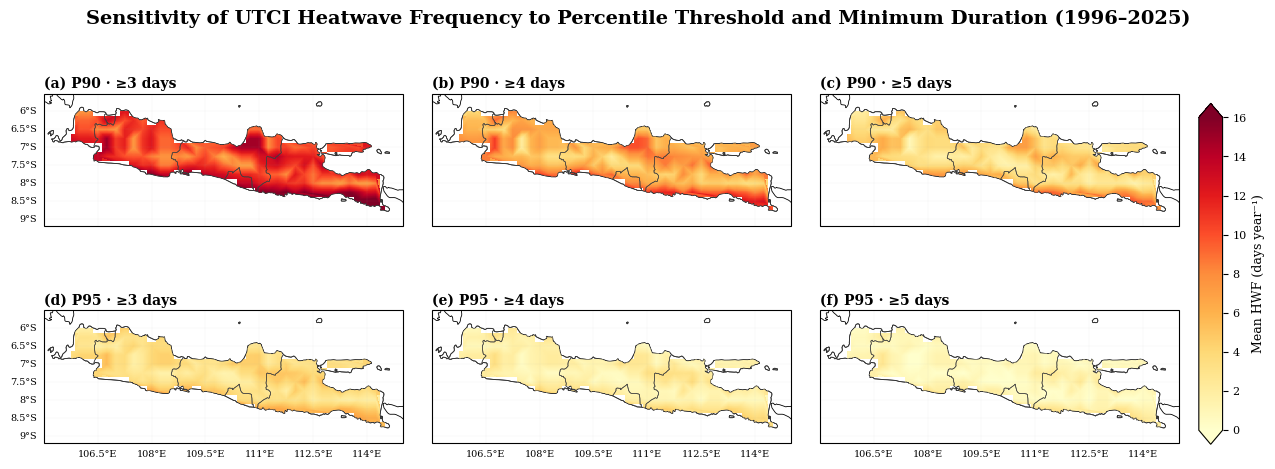

In [11]:
# ============================================================
# FIGURE 3 — SENSITIVITY SPATIAL HWF
# ============================================================

hwf_maps = {scenario: masked(np.nanmean(scenario_results[scenario]["HWF"], axis=0)) for scenario in SCENARIOS}
# Skala warna konsisten untuk keenam panel
svmin = 0
svmax = 16

fig = plt.figure(figsize=(13.2, 5.5))
gs = fig.add_gridspec(
    2, 3,
    wspace=0.08,
    hspace=0.02,  # Memperkecil jarak antarbaris
    left=0.05,
    right=0.91,
    bottom=0.10,
    top=0.88
)

mesh = None
for i, scenario in enumerate(SCENARIOS):
    row, col = i // 3, i % 3
    ax = fig.add_subplot(gs[row, col], projection=ccrs.PlateCarree())
    mesh = draw_spatial_field(
        ax, hwf_maps[scenario], cmap="YlOrRd", vmin=svmin, vmax=svmax,
    )
    p = int(re.search(r"P(\d+)", scenario).group(1))
    d = int(re.search(r"D(\d+)", scenario).group(1))
    setup_map_ax(ax, left_labels=(col == 0), bottom_labels=(row == 1))
    ax.set_title(f"({chr(97+i)}) P{p} · ≥{d} days", fontweight="bold", loc="left", pad=4)

cax = fig.add_axes([0.925, 0.17, 0.018, 0.62])
cb = fig.colorbar(mesh, cax=cax, orientation="vertical", extend="both", extendfrac=0.045, extendrect=False)
cb.set_label("Mean HWF (days year⁻¹)")

fig.suptitle(
    f"Sensitivity of UTCI Heatwave Frequency to Percentile Threshold and Minimum Duration ({START_YEAR}–{END_YEAR})",
    fontweight="bold", y=0.96,
)

save_figure(fig, "FIG03_Sensitivity_Spatial_HWF_UTCI_P90_P95_D3_D4_D5")
plt.show()
plt.close(fig)


## 10. Figure 4 — Sensitivitas time series lima karakteristik

Warna membedakan **minimum duration**, sedangkan garis solid/dashed membedakan **P90 vs P95**.


Tersimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\plots\FIG04_Sensitivity_TimeSeries_UTCI_All_Metrics.png


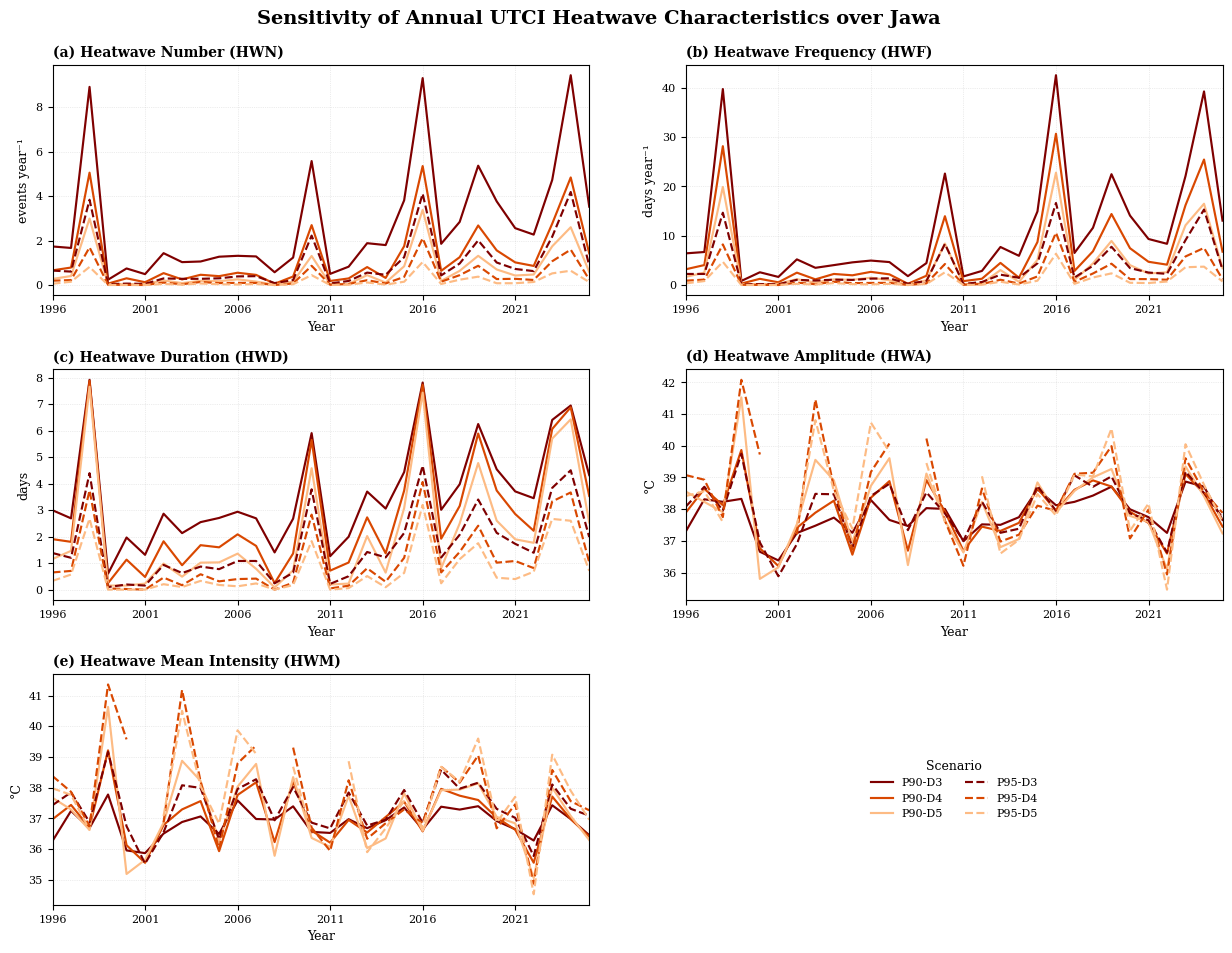

In [12]:
# ============================================================
# FIGURE 4 — SENSITIVITY TIME SERIES
# ============================================================

if INTENSITY_MODE == "absolute":
    hwa_metric, hwm_metric = "HWA_abs", "HWM_abs"
    intensity_unit = "°C"
else:
    hwa_metric, hwm_metric = "HWA_excess", "HWM_excess"
    intensity_unit = "°C above threshold"

plot_metrics = [
    ("HWN", "Heatwave Number (HWN)", "events year⁻¹"),
    ("HWF", "Heatwave Frequency (HWF)", "days year⁻¹"),
    ("HWD", "Heatwave Duration (HWD)", "days"),
    (hwa_metric, "Heatwave Amplitude (HWA)", intensity_unit),
    (hwm_metric, "Heatwave Mean Intensity (HWM)", intensity_unit),
]

duration_colors = {3: "#7f0000", 4: "#d94801", 5: "#fdbb84"}
percentile_styles = {90: "-", 95: "--"}

fig = plt.figure(figsize=(13.0, 10.0))
gs = fig.add_gridspec(3, 2, hspace=0.32, wspace=0.18, left=0.08, right=0.98, bottom=0.07, top=0.91)

axes = []
for i, (metric, title, ylabel) in enumerate(plot_metrics):
    ax = fig.add_subplot(gs[i // 2, i % 2])
    axes.append(ax)
    for scenario in SCENARIOS:
        p = int(re.search(r"P(\d+)", scenario).group(1))
        d = int(re.search(r"D(\d+)", scenario).group(1))
        sub = annual_df[annual_df["scenario"] == scenario].sort_values("year")
        ax.plot(
            sub["year"], sub[metric],
            color=duration_colors[d], linestyle=percentile_styles[p],
            linewidth=1.55, label=f"P{p}-D{d}",
        )
    ax.set_title(f"({chr(97+i)}) {title}", fontweight="bold", loc="left")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Year")
    ax.set_xlim(START_YEAR, END_YEAR)
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 5))
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.45)

ax_leg = fig.add_subplot(gs[2, 1])
ax_leg.axis("off")
handles, labels = axes[0].get_legend_handles_labels()
ax_leg.legend(handles, labels, loc="center", frameon=False, ncol=2, title="Scenario")

fig.suptitle(
    "Sensitivity of Annual UTCI Heatwave Characteristics over Jawa",
    fontweight="bold", y=0.965,
)

save_figure(fig, "FIG04_Sensitivity_TimeSeries_UTCI_All_Metrics")
plt.show()
plt.close(fig)


## 11. Figure 5 — Peta karakteristik heatwave UTCI

Figure utama mengikuti `MAIN_SCENARIO`.


Tersimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\plots\FIG05_Spatial_UTCI_Heatwave_Characteristics_P90_D3_absolute.png


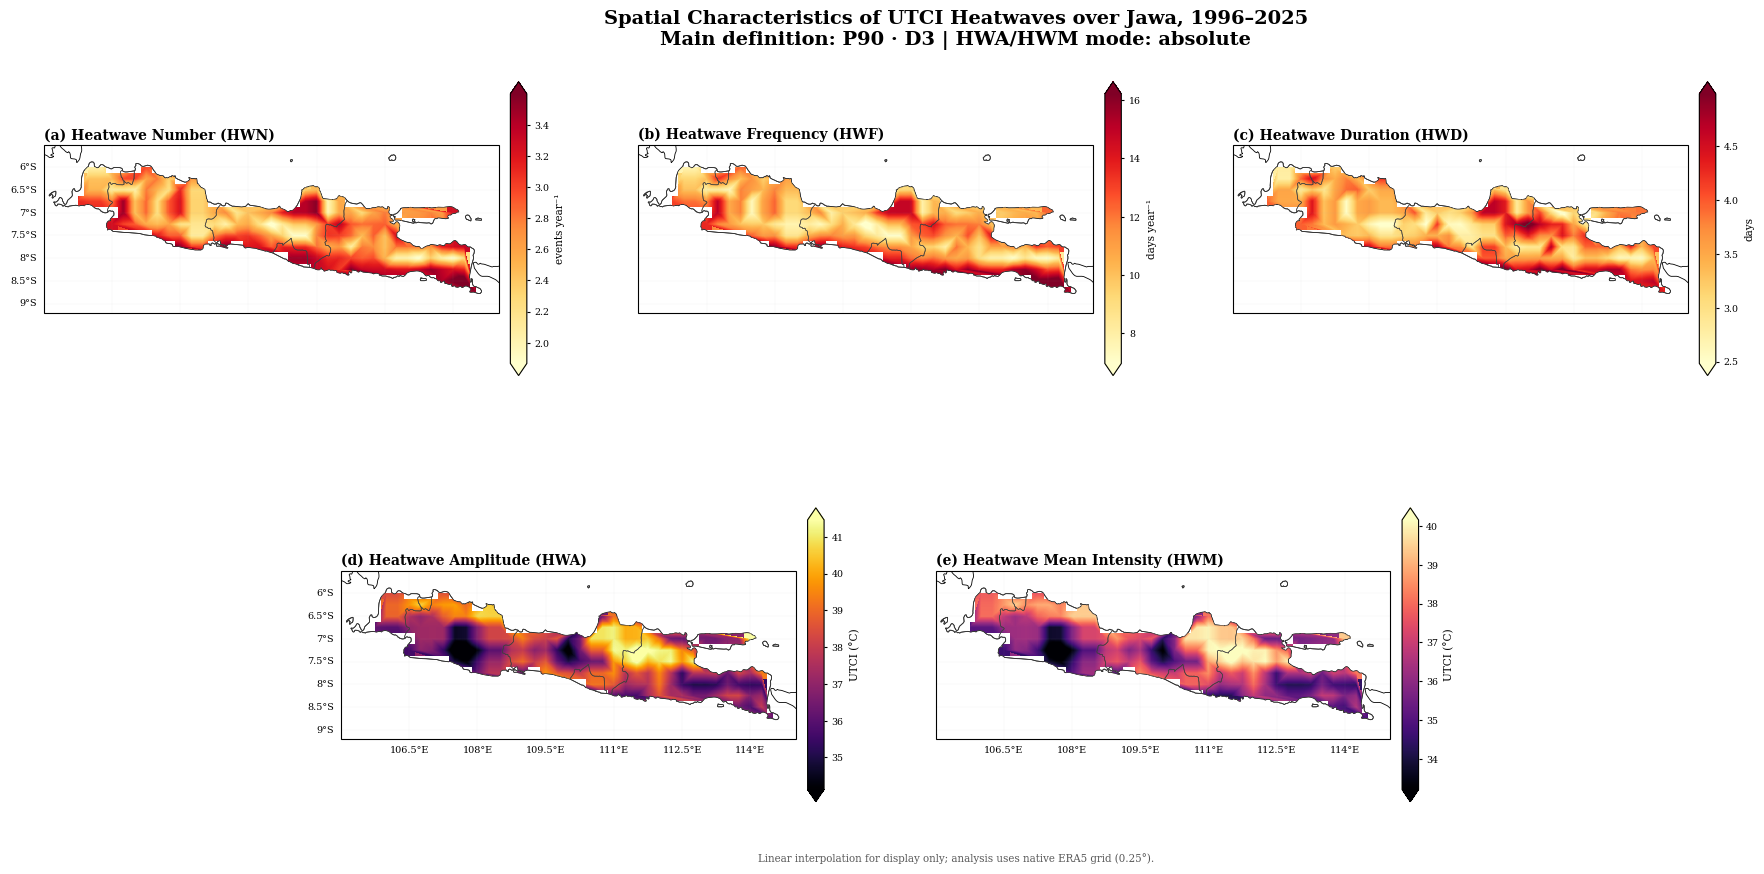

In [13]:
# ============================================================
# FIGURE 5 — SPATIAL CHARACTERISTICS UTCI HEATWAVES
# ============================================================

main = scenario_results[MAIN_SCENARIO]

if INTENSITY_MODE == "absolute":
    hwa_key, hwm_key = "HWA_abs", "HWM_abs"
    hwa_label, hwm_label = "UTCI (°C)", "UTCI (°C)"
else:
    hwa_key, hwm_key = "HWA_excess", "HWM_excess"
    hwa_label, hwm_label = "°C above threshold", "°C above threshold"

map_specs = [
    ("HWN", "Heatwave Number (HWN)", "events year⁻¹", "YlOrRd"),
    ("HWF", "Heatwave Frequency (HWF)", "days year⁻¹", "YlOrRd"),
    ("HWD", "Heatwave Duration (HWD)", "days", "YlOrRd"),
    (hwa_key, "Heatwave Amplitude (HWA)", hwa_label, "inferno"),
    (hwm_key, "Heatwave Mean Intensity (HWM)", hwm_label, "magma"),
]

positions = [(0, 0, 2), (0, 2, 2), (0, 4, 2), (1, 1, 2), (1, 3, 2)]
fig = plt.figure(figsize=(19, 9))

outer = fig.add_gridspec(
    2, 6,
    hspace=0.45,
    wspace=0.60,
    left=0.02,
    right=0.90,
    bottom=0.08,
    top=0.88)

for i, ((metric, title, unit, cmap), pos) in enumerate(zip(map_specs, positions)):
    row, col, colspan = pos
    inner = outer[row, col:col+colspan].subgridspec(1, 2, width_ratios=[0.965, 0.035], wspace=0.05)
    ax = fig.add_subplot(inner[0, 0], projection=ccrs.PlateCarree())
    z = masked(np.nanmean(main[metric], axis=0))
    vmin, vmax = robust_limits(z, low=2, high=98)
    mesh = draw_spatial_field(
        ax, z, cmap=cmap, vmin=vmin, vmax=vmax,
    )
    setup_map_ax(ax, left_labels=(col <= 1), bottom_labels=(row == 1))
    ax.set_title(f"({chr(97+i)}) {title}", fontweight="bold", loc="left", pad=4)
    cax = fig.add_subplot(inner[0, 1])
    cb = fig.colorbar(mesh, cax=cax, orientation="vertical", extend="both", extendfrac=0.045, extendrect=False)
    cb.set_label(unit, fontsize=7.5)
    cb.ax.tick_params(labelsize=6.8, length=2)

fig.suptitle(
    f"Spatial Characteristics of UTCI Heatwaves over Jawa, {START_YEAR}–{END_YEAR}\n"
    f"Main definition: {MAIN_SCENARIO.replace('_', ' · ')} | HWA/HWM mode: {INTENSITY_MODE}",
    fontweight="bold", y=0.96,
)

fig.text(0.50, 0.013, "Linear interpolation for display only; analysis uses native ERA5 grid (0.25°).",
         fontsize=7.4, ha="center", color="0.35")

save_figure(fig, f"FIG05_Spatial_UTCI_Heatwave_Characteristics_{MAIN_SCENARIO}_{INTENSITY_MODE}")
plt.show()
plt.close(fig)


## 12. Figure 6 — Time series utama + Theil–Sen trend

Format mengikuti plot jurnal yang kamu suka:
- garis abu tipis = nilai tahunan;
- garis merah = running mean 5 tahun;
- garis hitam putus = Theil–Sen trend;
- kotak anotasi = slope per decade + p-value Kendall.


Tersimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\plots\FIG06_Main_TimeSeries_UTCI_TheilSen_P90_D3_absolute.png


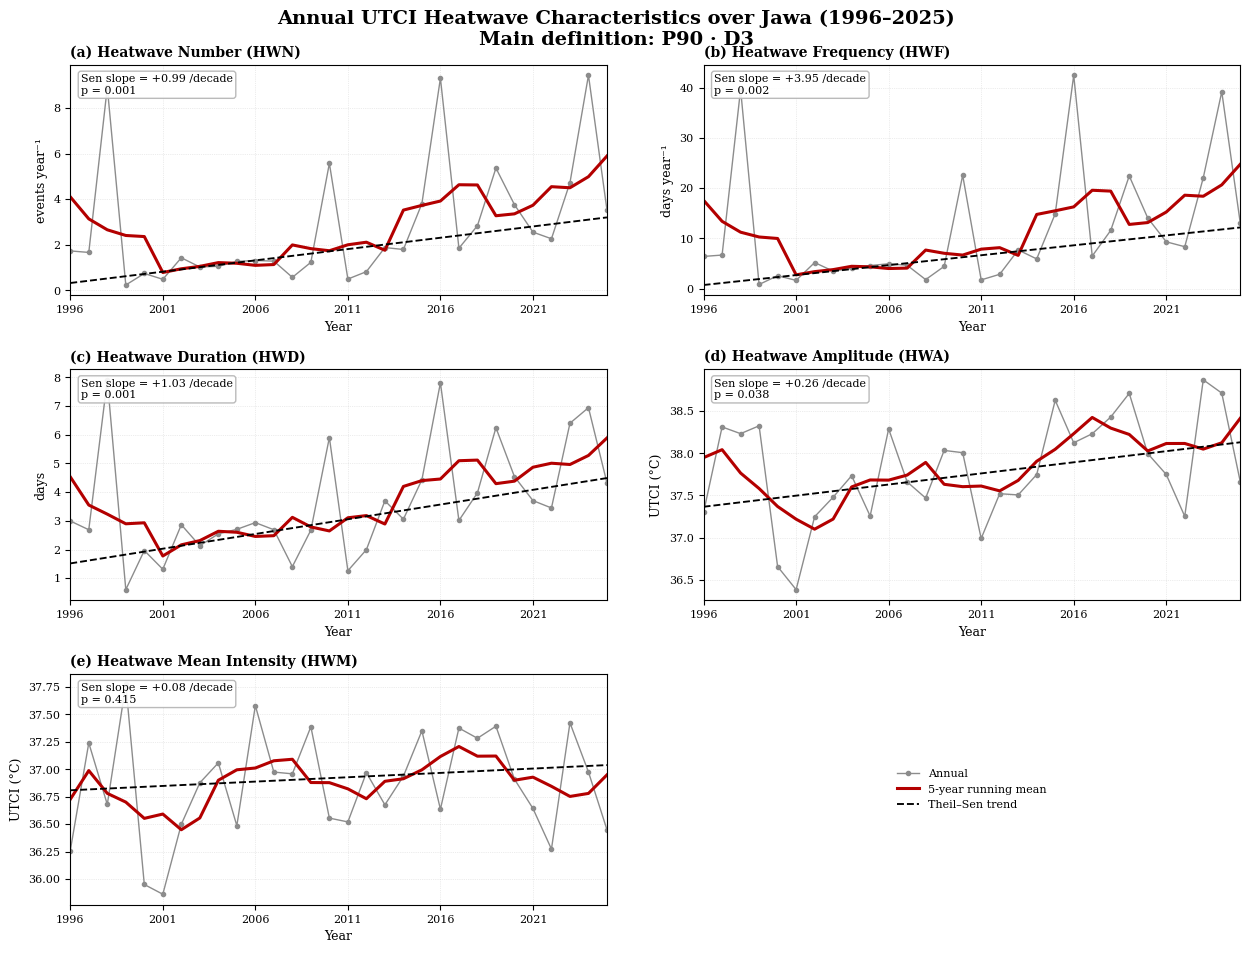

,metric,slope_per_decade,kendall_p
0,HWN,0.991463,0.001150
1,HWF,3.951003,0.001966
2,HWD,1.025773,0.000870
3,HWA_abs,0.263555,0.037701
4,HWM_abs,0.079143,0.415105


In [14]:
# ============================================================
# FIGURE 6 — MAIN TIME SERIES + THEIL-SEN + KENDALL
# ============================================================

main_df = annual_df[annual_df["scenario"] == MAIN_SCENARIO].sort_values("year").copy()

main_metrics = [
    ("HWN", "Heatwave Number (HWN)", "events year⁻¹"),
    ("HWF", "Heatwave Frequency (HWF)", "days year⁻¹"),
    ("HWD", "Heatwave Duration (HWD)", "days"),
    (hwa_key, "Heatwave Amplitude (HWA)", hwa_label),
    (hwm_key, "Heatwave Mean Intensity (HWM)", hwm_label),
]

fig = plt.figure(figsize=(13.0, 10.0))
gs = fig.add_gridspec(3, 2, hspace=0.32, wspace=0.18, left=0.08, right=0.98, bottom=0.07, top=0.91)

trend_rows = []
legend_handles = None
legend_labels = None

for i, (metric, title, ylabel) in enumerate(main_metrics):
    ax = fig.add_subplot(gs[i // 2, i % 2])
    x = main_df["year"].to_numpy(dtype=float)
    y = main_df[metric].to_numpy(dtype=float)
    valid_xy = np.isfinite(x) & np.isfinite(y)

    line1, = ax.plot(x, y, color="0.55", linewidth=1.0, marker="o", markersize=3.0, label="Annual")
    rolling = pd.Series(y).rolling(5, center=True, min_periods=3).mean().to_numpy()
    line2, = ax.plot(x, rolling, color="#b30000", linewidth=2.2, label="5-year running mean")

    if valid_xy.sum() >= 10:
        ts = theilslopes(y[valid_xy], x[valid_xy], alpha=0.95)
        trend = ts.intercept + ts.slope * x
        mk = kendalltau(x[valid_xy], y[valid_xy], nan_policy="omit")
        line3, = ax.plot(x, trend, color="black", linestyle="--", linewidth=1.35, label="Theil–Sen trend")
        slope_dec = ts.slope * 10.0
        pval = mk.pvalue
        ax.text(
            0.02, 0.96,
            f"Sen slope = {slope_dec:+.2f} /decade\np = {pval:.3f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="0.7", alpha=0.9),
        )
        trend_rows.append({"metric": metric, "slope_per_decade": slope_dec, "kendall_p": pval})
    else:
        line3 = None

    if legend_handles is None:
        legend_handles = [h for h in [line1, line2, line3] if h is not None]
        legend_labels = [h.get_label() for h in legend_handles]

    ax.set_title(f"({chr(97+i)}) {title}", fontweight="bold", loc="left")
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.set_xlim(START_YEAR, END_YEAR)
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 5))
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.45)

ax_leg = fig.add_subplot(gs[2, 1])
ax_leg.axis("off")
ax_leg.legend(legend_handles, legend_labels, loc="center", frameon=False)

fig.suptitle(
    f"Annual UTCI Heatwave Characteristics over Jawa ({START_YEAR}–{END_YEAR})\n"
    f"Main definition: {MAIN_SCENARIO.replace('_', ' · ')}",
    fontweight="bold", y=0.965,
)

save_figure(fig, f"FIG06_Main_TimeSeries_UTCI_TheilSen_{MAIN_SCENARIO}_{INTENSITY_MODE}")
plt.show()
plt.close(fig)

trend_summary_df = pd.DataFrame(trend_rows)
trend_summary_df


Main scenario : P90_D3
Intensity mode: absolute
Banten              : 10 grid
DKI Jakarta         : 1 grid
Jawa Barat          : 50 grid
Jawa Tengah         : 47 grid
DI Yogyakarta       : 3 grid
Jawa Timur          : 65 grid

Regional UTCI dataframe:


,year,region,metric,value
0,1996,Banten,HWN,0.699615
1,1996,Banten,HWF,2.298707
2,1996,Banten,HWD,1.399329
3,1996,Banten,HWA_abs,36.018109
4,1996,Banten,HWM_abs,35.290918
5,1996,DKI Jakarta,HWN,0.000000
6,1996,DKI Jakarta,HWF,0.000000
7,1996,DKI Jakarta,HWD,0.000000
8,1996,DKI Jakarta,HWA_abs,NaN
9,1996,DKI Jakarta,HWM_abs,NaN


,region,metric,count,mean,min,max
0,Banten,HWA_abs,30,37.765846,34.884705,39.977097
1,Banten,HWD,30,3.309827,0.599585,9.498675
2,Banten,HWF,30,10.132433,0.599585,50.093926
3,Banten,HWM_abs,30,36.981814,34.419086,38.321327
4,Banten,HWN,30,2.556474,0.199862,11.598677
5,DI Yogyakarta,HWA_abs,25,38.848653,37.302130,39.943115
6,DI Yogyakarta,HWD,30,3.633186,0.000000,11.333065
7,DI Yogyakarta,HWF,30,13.177541,0.000000,78.000402
8,DI Yogyakarta,HWM_abs,25,37.654285,36.339074,38.978992
9,DI Yogyakarta,HWN,30,3.377729,0.000000,16.666533


Tersimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\plots\FIG07_Province_TimeSeries_UTCI_P90_D3_absolute.png


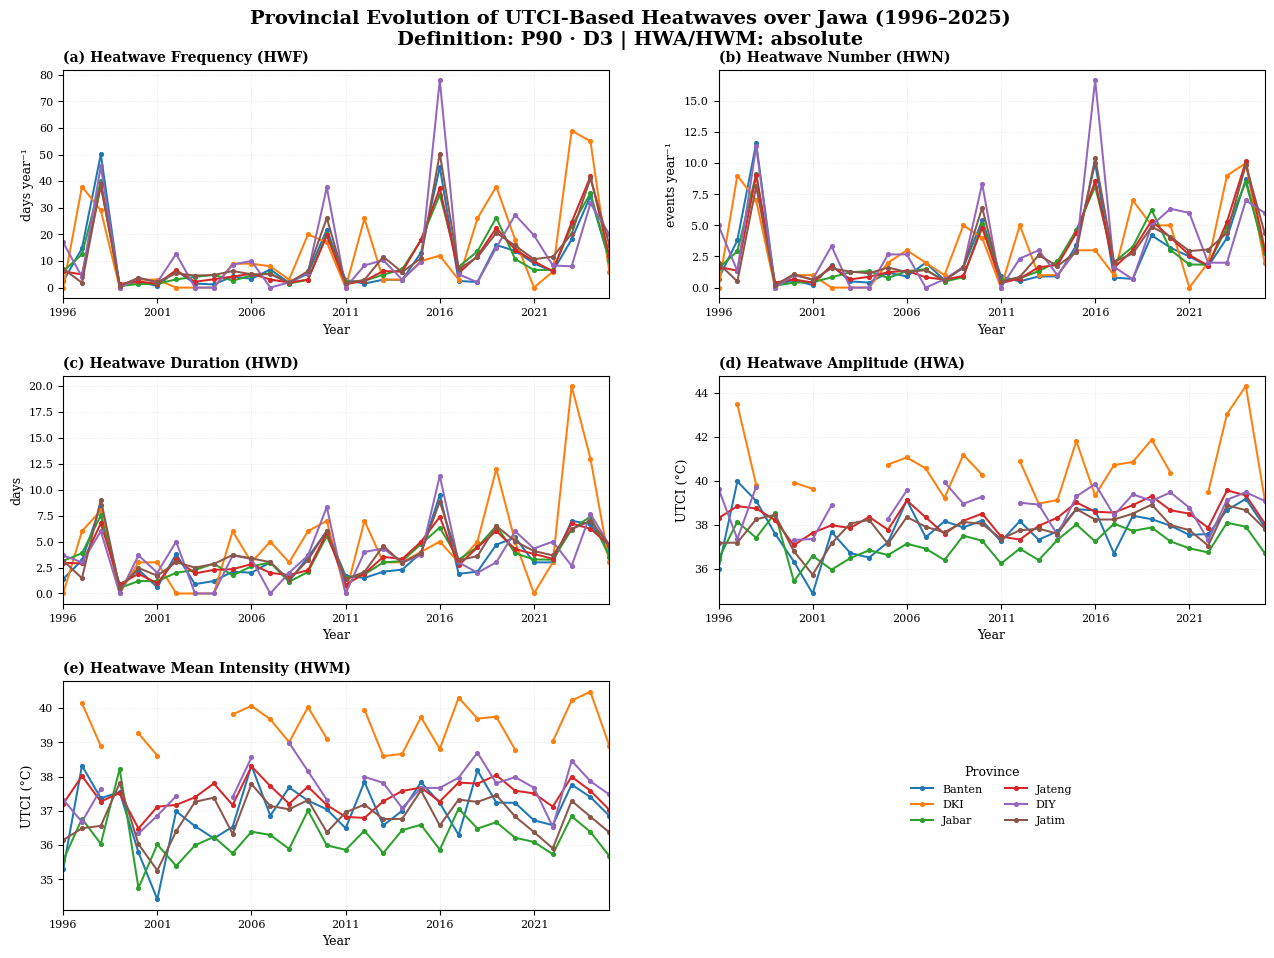

CSV tersimpan: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\data\UTCI_Province_TimeSeries_P90_D3_absolute.csv


In [15]:
# ============================================================
# FIGURE 7 — PROVINCE TIME SERIES UTCI (MAIN SCENARIO)
# HWN, HWF, HWD, HWA, HWM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.io.shapereader as shpreader

# ------------------------------------------------------------
# 1. PASTIKAN YEAR AXIS TERSEDIA
# ------------------------------------------------------------

if "years" in globals():
    YEAR_AXIS = np.asarray(years, dtype=int)
elif "YEARS" in globals():
    YEAR_AXIS = np.asarray(YEARS, dtype=int)
else:
    YEAR_AXIS = np.arange(START_YEAR, END_YEAR + 1)

# ------------------------------------------------------------
# 2. GRID 2-D
# ------------------------------------------------------------

lon2d, lat2d = np.meshgrid(lon, lat)

# ------------------------------------------------------------
# 3. DEFINISI HWA / HWM
# ------------------------------------------------------------

if INTENSITY_MODE == "absolute":
    hwa_key = "HWA_abs"
    hwm_key = "HWM_abs"

    hwa_label = "UTCI (°C)"
    hwm_label = "UTCI (°C)"

else:
    hwa_key = "HWA_excess"
    hwm_key = "HWM_excess"

    hwa_label = "°C above threshold"
    hwm_label = "°C above threshold"

# ------------------------------------------------------------
# 4. DATA SKENARIO UTAMA
# ------------------------------------------------------------

main = scenario_results[MAIN_SCENARIO]

print("Main scenario :", MAIN_SCENARIO)
print("Intensity mode:", INTENSITY_MODE)


# ============================================================
# 5. PROVINSI JAWA (PAKAI GEOMETRI DARI HELPER PETA)
# ============================================================
province_order = JAVA_PROVINCE_ORDER.copy()
province_short = JAVA_PROVINCE_SHORT.copy()
# province_masks sudah dibentuk memakai grid UTCI yang benar di sel helper.
for province in province_order:
    n = int(province_masks[province].sum())
    print(f"{province:20s}: {n} grid")
    if n == 0:
        warnings.warn(f"Tidak ada titik grid valid untuk {province}; "
                      "hasil provinsi akan NaN pada resolusi saat ini.")


# ============================================================
# 6. AREA-WEIGHTED MEAN
# ============================================================

def regional_weighted_mean(
    field,
    region_mask
):

    """
    Area-weighted mean menggunakan cos(latitude).
    """

    field = np.asarray(
        field,
        dtype=float
    )

    region_mask = np.asarray(
        region_mask,
        dtype=bool
    )

    weights = np.where(
        region_mask,
        np.cos(
            np.deg2rad(
                lat2d
            )
        ),
        np.nan
    )

    valid_mask = (
        np.isfinite(field)
        &
        np.isfinite(weights)
    )

    if not np.any(
        valid_mask
    ):
        return np.nan

    return float(
        np.nansum(
            field[valid_mask]
            *
            weights[valid_mask]
        )
        /
        np.nansum(
            weights[valid_mask]
        )
    )


# ============================================================
# 7. BANGUN DATAFRAME PROVINSI
# ============================================================

metrics_to_extract = [
    "HWN",
    "HWF",
    "HWD",
    hwa_key,
    hwm_key,
]


regional_rows = []


for yi, year in enumerate(
    YEAR_AXIS
):

    for province in province_order:

        region_mask = province_masks[
            province
        ]

        for metric in metrics_to_extract:

            value = regional_weighted_mean(
                main[metric][yi],
                region_mask
            )

            regional_rows.append(
                {
                    "year": int(year),
                    "region": province,
                    "metric": metric,
                    "value": value,
                }
            )


regional_utci_df = pd.DataFrame(
    regional_rows
)


print("\nRegional UTCI dataframe:")
display(
    regional_utci_df.head(15)
)


# ============================================================
# 8. QC MISSING VALUE
# ============================================================

qc_province = (
    regional_utci_df
    .groupby(
        ["region", "metric"]
    )["value"]
    .agg(
        [
            "count",
            "mean",
            "min",
            "max"
        ]
    )
    .reset_index()
)

display(
    qc_province
)


# ============================================================
# 9. FIGURE — PROVINCE TIME SERIES
# ============================================================

province_metrics = [
    (
        "HWF",
        "Heatwave Frequency (HWF)",
        "days year⁻¹"
    ),
    (
        "HWN",
        "Heatwave Number (HWN)",
        "events year⁻¹"
    ),
    (
        "HWD",
        "Heatwave Duration (HWD)",
        "days"
    ),
    (
        hwa_key,
        "Heatwave Amplitude (HWA)",
        hwa_label
    ),
    (
        hwm_key,
        "Heatwave Mean Intensity (HWM)",
        hwm_label
    ),
]


fig = plt.figure(
    figsize=(13.5, 10.0)
)

gs = fig.add_gridspec(
    3,
    2,
    hspace=0.34,
    wspace=0.20,
    left=0.08,
    right=0.97,
    bottom=0.07,
    top=0.91,
)


axes = []


for i, (
    metric,
    title,
    ylabel
) in enumerate(
    province_metrics
):

    ax = fig.add_subplot(
        gs[
            i // 2,
            i % 2
        ]
    )

    axes.append(
        ax
    )


    for province in province_order:

        sub = regional_utci_df[
            (
                regional_utci_df[
                    "region"
                ]
                == province
            )
            &
            (
                regional_utci_df[
                    "metric"
                ]
                == metric
            )
        ].sort_values(
            "year"
        )


        ax.plot(
            sub["year"],
            sub["value"],
            linewidth=1.45,
            marker="o",
            markersize=2.7,
            label=province_short[
                province
            ],
        )


    ax.set_title(
        f"({chr(97+i)}) {title}",
        fontweight="bold",
        loc="left",
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_xlim(
        START_YEAR,
        END_YEAR
    )

    ax.set_xticks(
        np.arange(
            START_YEAR,
            END_YEAR + 1,
            5
        )
    )

    ax.grid(
        True,
        linestyle=":",
        linewidth=0.5,
        alpha=0.4,
    )


# ============================================================
# 10. PANEL LEGEND
# ============================================================

ax_leg = fig.add_subplot(
    gs[2, 1]
)

ax_leg.axis(
    "off"
)


handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)


ax_leg.legend(
    handles,
    labels,
    loc="center",
    frameon=False,
    ncol=2,
    fontsize=8,
    title="Province",
)


# X label hanya panel bawah
axes[4].set_xlabel(
    "Year"
)

# panel lain yang ada di row terakhir kalau diperlukan
for ax in axes[:4]:
    ax.set_xlabel(
        "Year"
    )


# ============================================================
# 11. TITLE
# ============================================================

fig.suptitle(
    f"Provincial Evolution of UTCI-Based Heatwaves over Jawa "
    f"({START_YEAR}–{END_YEAR})\n"
    f"Definition: {MAIN_SCENARIO.replace('_', ' · ')} | "
    f"HWA/HWM: {INTENSITY_MODE}",
    fontweight="bold",
    y=0.97,
)


# ============================================================
# 12. SAVE
# ============================================================

save_figure(
    fig,
    f"FIG07_Province_TimeSeries_UTCI_"
    f"{MAIN_SCENARIO}_"
    f"{INTENSITY_MODE}"
)

plt.show()
plt.close(
    fig
)


# ============================================================
# 13. EXPORT CSV
# ============================================================

province_csv = (
    DATA_DIR
    / (
        f"UTCI_Province_TimeSeries_"
        f"{MAIN_SCENARIO}_"
        f"{INTENSITY_MODE}.csv"
    )
)

regional_utci_df.to_csv(
    province_csv,
    index=False
)

print(
    "CSV tersimpan:",
    province_csv
)

## 13. Ringkasan sensitivity + ekspor Excel

Output tabel yang disimpan:
- annual metrics semua skenario;
- summary sensitivitas 30 tahun;
- summary threshold;
- trend summary untuk definisi utama.


In [16]:
# ============================================================
# 13. SUMMARY TABLE + EXPORT
# ============================================================

summary_rows = []
for scenario in SCENARIOS:
    sub = annual_df[annual_df["scenario"] == scenario]
    p = int(re.search(r"P(\d+)", scenario).group(1))
    d = int(re.search(r"D(\d+)", scenario).group(1))
    summary_rows.append({
        "scenario": scenario,
        "percentile": p,
        "min_duration_days": d,
        "HWN_mean": sub["HWN"].mean(),
        "HWF_mean_days_per_year": sub["HWF"].mean(),
        "HWD_mean_days": sub["HWD"].mean(),
        "HWA_abs_mean_C": sub["HWA_abs"].mean(),
        "HWM_abs_mean_C": sub["HWM_abs"].mean(),
        "HWA_excess_mean_C": sub["HWA_excess"].mean(),
        "HWM_excess_mean_C": sub["HWM_excess"].mean(),
    })

sensitivity_summary_df = pd.DataFrame(summary_rows)
threshold_summary_df = pd.DataFrame([
    {
        "threshold": key,
        "mean_C": float(np.nanmean(arr)),
        "min_C": float(np.nanmin(arr)),
        "max_C": float(np.nanmax(arr)),
    }
    for key, arr in thresholds.items()
])

annual_csv = DATA_DIR / "Annual_UTCI_Heatwave_Metrics_All_Scenarios.csv"
annual_df.to_csv(annual_csv, index=False)

excel_path = DATA_DIR / "UTCI_Heatwave_Journal_Combined_1996_2025.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    annual_df.to_excel(writer, sheet_name="Annual_Metrics", index=False)
    sensitivity_summary_df.to_excel(writer, sheet_name="Sensitivity_Summary", index=False)
    threshold_summary_df.to_excel(writer, sheet_name="Threshold_Summary", index=False)
    trend_summary_df.to_excel(writer, sheet_name="Trend_Main", index=False)

print("CSV  :", annual_csv)
print("Excel:", excel_path)
print("\nPlot folder:", PLOT_DIR)
print("\nDaftar PNG:")
for p in sorted(PLOT_DIR.glob("*.png")):
    print(" -", p.name)


CSV  : D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\data\Annual_UTCI_Heatwave_Metrics_All_Scenarios.csv
Excel: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\data\UTCI_Heatwave_Journal_Combined_1996_2025.xlsx

Plot folder: D:\Daps\Data\UTCI\Hasil_UTCI_Jawa_1996_2025\UTCI_Heatwave_Jawa_Journal_Combined_Output\plots

Daftar PNG:
 - FIG01_Mean_Daily_UTCImax_Jawa_1996_2025.png
 - FIG02_P90_P95_Threshold_Comparison_UTCI.png
 - FIG03_Sensitivity_Spatial_HWF_UTCI_P90_P95_D3_D4_D5.png
 - FIG04_Sensitivity_TimeSeries_UTCI_All_Metrics.png
 - FIG05_Spatial_UTCI_Heatwave_Characteristics_P90_D3_absolute.png
 - FIG06_Main_TimeSeries_UTCI_TheilSen_P90_D3_absolute.png
 - FIG07_Province_TimeSeries_UTCI_P90_D3_absolute.png


## 14. Daftar output akhir

Target output utama yang akan muncul di folder `plots`:
- `FIG01_Mean_Daily_UTCImax_Jawa_1996_2025`
- `FIG02_P90_P95_Threshold_Comparison_UTCI`
- `FIG03_Sensitivity_Spatial_HWF_UTCI_P90_P95_D3_D4_D5`
- `FIG04_Sensitivity_TimeSeries_UTCI_All_Metrics`
- `FIG05_Spatial_UTCI_Heatwave_Characteristics_<MAIN_SCENARIO>_<INTENSITY_MODE>`
- `FIG06_Main_TimeSeries_UTCI_TheilSen_<MAIN_SCENARIO>_<INTENSITY_MODE>`

Kalau kamu mau versi utama **P95-D3**, ganti saja:

```python
MAIN_SCENARIO = "P95_D3"
```

Kalau kamu mau HWA/HWM sebagai **excess above threshold**, ganti:

```python
INTENSITY_MODE = "excess"
```
